In [ ]:
import pandas as pd

df = pd.read_csv("/content/Train new.csv")

# Melihat tabel
df.head()

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


In [ ]:
df.shape

(10999, 12)

In [ ]:
df.columns.tolist()

['ID',
 'Warehouse_block',
 'Mode_of_Shipment',
 'Customer_care_calls',
 'Customer_rating',
 'Cost_of_the_Product',
 'Prior_purchases',
 'Product_importance',
 'Gender',
 'Discount_offered',
 'Weight_in_gms',
 'Reached.on.Time_Y.N']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 
 10  Weight_in_gms        10999 non-null  int64 
 11  Reached.on.Time_Y.N  10999 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 1.0+ MB


In [ ]:
df.describe()

,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
count,10999.00000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000
mean,5500.00000,4.054459,2.990545,210.196836,3.567597,13.373216,3634.016729,0.596691
std,3175.28214,1.141490,1.413603,48.063272,1.522860,16.205527,1635.377251,0.490584
min,1.00000,2.000000,1.000000,96.000000,2.000000,1.000000,1001.000000,0.000000
25%,2750.50000,3.000000,2.000000,169.000000,3.000000,4.000000,1839.500000,0.000000
50%,5500.00000,4.000000,3.000000,214.000000,3.000000,7.000000,4149.000000,1.000000
75%,8249.50000,5.000000,4.000000,251.000000,4.000000,10.000000,5050.000000,1.000000
max,10999.00000,7.000000,5.000000,310.000000,10.000000,65.000000,7846.000000,1.000000


In [ ]:
df.describe(include='object')

,Warehouse_block,Mode_of_Shipment,Product_importance,Gender
count,10999,10999,10999,10999
unique,5,3,3,2
top,F,Ship,low,F
freq,3666,7462,5297,5545


In [ ]:
df.isnull().sum()

,0
ID,0
Warehouse_block,0
Mode_of_Shipment,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Product_importance,0
Gender,0
Discount_offered,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
for col in df.select_dtypes(include='object').columns:
    print(col, df[col].unique())

Warehouse_block ['D' 'F' 'A' 'B' 'C']
Mode_of_Shipment ['Flight' 'Ship' 'Road']
Product_importance ['low' 'medium' 'high']
Gender ['F' 'M']


In [ ]:
# Menghitung distribusi frekuensi
frekuensi = df['Reached.on.Time_Y.N'].value_counts().sort_index()

# Menghitung distribusi persentase
persentase = df['Reached.on.Time_Y.N'].value_counts(normalize=True).sort_index() * 100

# Membuat tabel distribusi
distribusi = pd.DataFrame({
    'Frekuensi': frekuensi,
    'Persentase (%)': persentase
})

# Mengubah kode status menjadi keterangan
distribusi.index = ['Tepat Waktu (0)', 'Terlambat (1)']

print(distribusi)

                 Frekuensi  Persentase (%)
Tepat Waktu (0)       4436       40.330939
Terlambat (1)         6563       59.669061


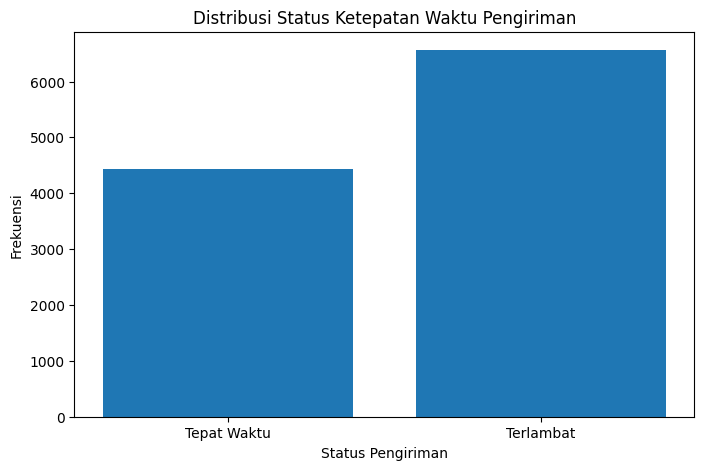

In [ ]:
import matplotlib.pyplot as plt

# Membuat bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    ['Tepat Waktu', 'Terlambat'],
    distribusi['Frekuensi']
)

plt.title('Distribusi Status Ketepatan Waktu Pengiriman')
plt.xlabel('Status Pengiriman')
plt.ylabel('Frekuensi')
plt.show()

In [ ]:
# Menghitung jumlah pengiriman berdasarkan moda dan status
frekuensi = pd.crosstab(
    df['Mode_of_Shipment'],
    df['Reached.on.Time_Y.N']
)

# Menghitung persentase keterlambatan pada setiap moda
persentase = pd.crosstab(
    df['Mode_of_Shipment'],
    df['Reached.on.Time_Y.N'],
    normalize='index'
) * 100

# Mengambil kolom status 1 (terlambat)
hasil = pd.DataFrame({
    'Jumlah Pengiriman': frekuensi.sum(axis=1),
    'Jumlah Terlambat': frekuensi[1],
    'Persentase Terlambat (%)': persentase[1]
})

print(hasil)

                  Jumlah Pengiriman  Jumlah Terlambat  \
Mode_of_Shipment                                        
Flight                         1777              1069   
Road                           1760              1035   
Ship                           7462              4459   

                  Persentase Terlambat (%)  
Mode_of_Shipment                            
Flight                           60.157569  
Road                             58.806818  
Ship                             59.756098  


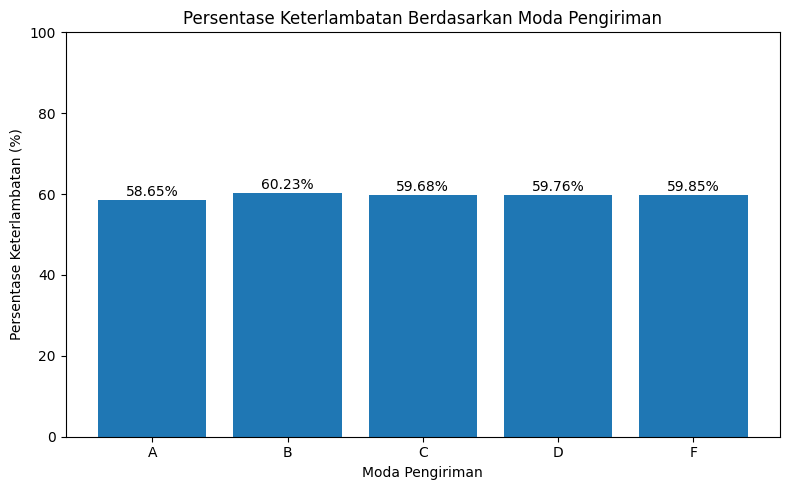

In [ ]:
import matplotlib.pyplot as plt

# Membuat bar chart persentase keterlambatan
plt.figure(figsize=(8, 5))

plt.bar(
    hasil.index,
    hasil['Persentase Terlambat (%)']
)

# Memberikan judul dan label
plt.title('Persentase Keterlambatan Berdasarkan Moda Pengiriman')
plt.xlabel('Moda Pengiriman')
plt.ylabel('Persentase Keterlambatan (%)')

# Mengatur skala sumbu Y
plt.ylim(0, 100)

# Menampilkan nilai persentase di atas batang
for i, nilai in enumerate(hasil['Persentase Terlambat (%)']):
    plt.text(i, nilai + 1, f'{nilai:.2f}%', ha='center')

plt.tight_layout()
plt.show()

In [ ]:
# Statistik deskriptif berat produk berdasarkan status pengiriman
hasil = df.groupby('Reached.on.Time_Y.N')['Weight_in_gms'].describe()

# Mengubah kode status menjadi keterangan
hasil.index = ['Tepat Waktu (0)', 'Terlambat (1)']

print(hasil)

                  count         mean          std     min     25%     50%  \
Tepat Waktu (0)  4436.0  4168.668395  1573.954178  1001.0  4043.5  4674.0   
Terlambat (1)    6563.0  3272.640104  1576.148391  1001.0  1735.5  3231.0   

                    75%     max  
Tepat Waktu (0)  5337.0  6000.0  
Terlambat (1)    4696.5  7846.0  


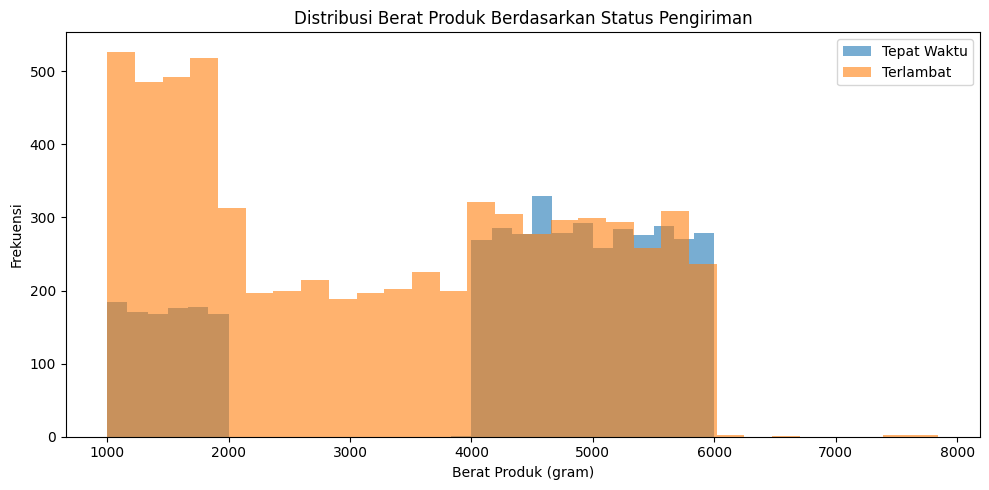

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Distribusi berat produk berdasarkan status pengiriman
plt.hist(
    df[df['Reached.on.Time_Y.N'] == 0]['Weight_in_gms'],
    bins=30,
    alpha=0.6,
    label='Tepat Waktu'
)

plt.hist(
    df[df['Reached.on.Time_Y.N'] == 1]['Weight_in_gms'],
    bins=30,
    alpha=0.6,
    label='Terlambat'
)

plt.title('Distribusi Berat Produk Berdasarkan Status Pengiriman')
plt.xlabel('Berat Produk (gram)')
plt.ylabel('Frekuensi')
plt.legend()

plt.tight_layout()
plt.show()

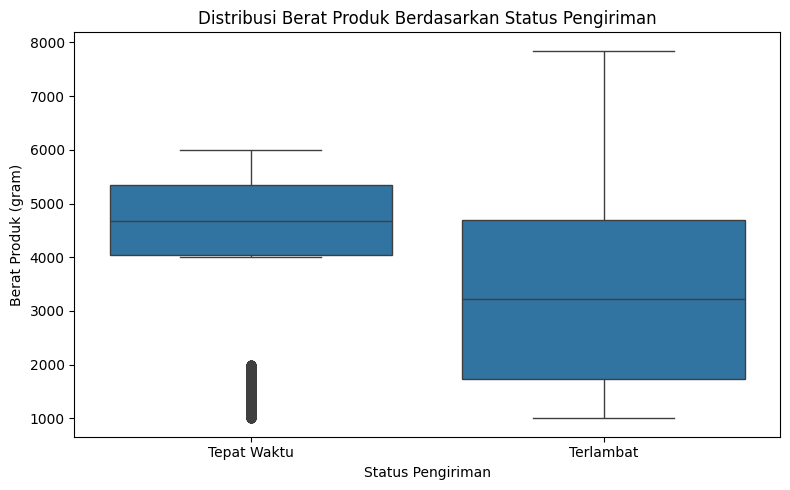

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Reached.on.Time_Y.N',
    y='Weight_in_gms'
)

plt.title('Distribusi Berat Produk Berdasarkan Status Pengiriman')
plt.xlabel('Status Pengiriman')
plt.ylabel('Berat Produk (gram)')

plt.xticks(
    [0, 1],
    ['Tepat Waktu', 'Terlambat']
)

plt.tight_layout()
plt.show()

In [ ]:
# Menghitung frekuensi pengiriman berdasarkan blok gudang dan status
frekuensi = pd.crosstab(
    df['Warehouse_block'],
    df['Reached.on.Time_Y.N']
)

# Menghitung persentase berdasarkan masing-masing blok gudang
persentase = pd.crosstab(
    df['Warehouse_block'],
    df['Reached.on.Time_Y.N'],
    normalize='index'
) * 100

# Membuat tabel perbandingan tingkat keterlambatan
hasil = pd.DataFrame({
    'Jumlah Pengiriman': frekuensi.sum(axis=1),
    'Jumlah Terlambat': frekuensi[1],
    'Persentase Terlambat (%)': persentase[1]
})

print(hasil)

                 Jumlah Pengiriman  Jumlah Terlambat  Persentase Terlambat (%)
Warehouse_block                                                               
A                             1833              1075                 58.647027
B                             1833              1104                 60.229133
C                             1833              1094                 59.683579
D                             1834              1096                 59.760087
F                             3666              2194                 59.847245


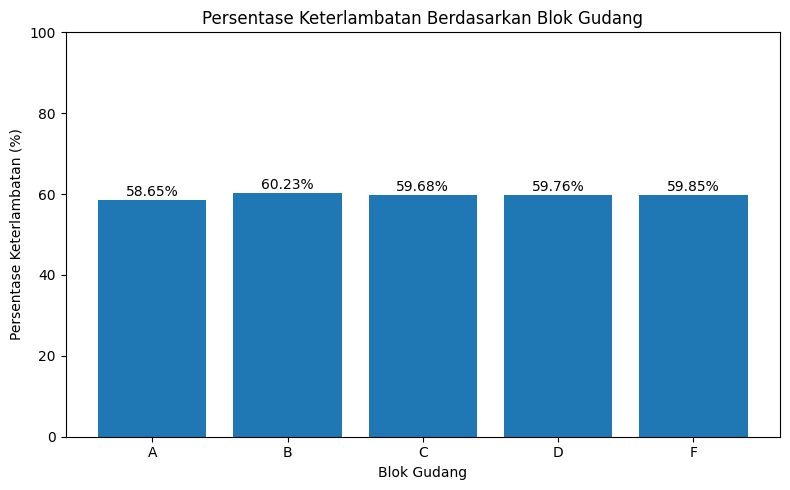

In [ ]:
import matplotlib.pyplot as plt

# Membuat bar chart persentase keterlambatan antarblok gudang
plt.figure(figsize=(8, 5))

plt.bar(
    hasil.index,
    hasil['Persentase Terlambat (%)']
)

# Memberikan judul dan label
plt.title('Persentase Keterlambatan Berdasarkan Blok Gudang')
plt.xlabel('Blok Gudang')
plt.ylabel('Persentase Keterlambatan (%)')

# Mengatur skala sumbu Y
plt.ylim(0, 100)

# Menampilkan nilai persentase di atas setiap batang
for i, nilai in enumerate(hasil['Persentase Terlambat (%)']):
    plt.text(i, nilai + 1, f'{nilai:.2f}%', ha='center')

plt.tight_layout()
plt.show()

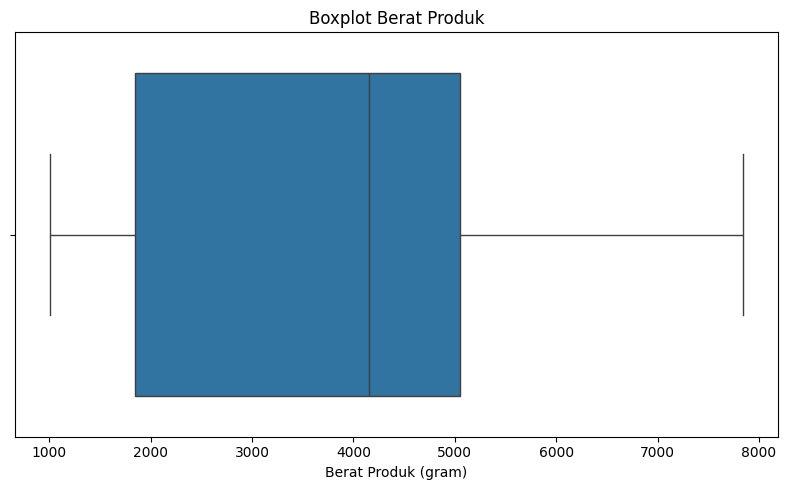

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(x=df['Weight_in_gms'])

plt.title('Boxplot Berat Produk')
plt.xlabel('Berat Produk (gram)')

plt.tight_layout()
plt.show()

In [27]:
# Menghitung kuartil pertama dan ketiga
Q1 = df['Weight_in_gms'].quantile(0.25)
Q3 = df['Weight_in_gms'].quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menentukan batas bawah dan batas atas
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# Mengidentifikasi outliers
outliers = df[
    (df['Weight_in_gms'] < batas_bawah) |
    (df['Weight_in_gms'] > batas_atas)
]

print('Q1:', Q1)
print('Q3:', Q3)
print('IQR:', IQR)
print('Batas bawah:', batas_bawah)
print('Batas atas:', batas_atas)
print('Jumlah outliers:', len(outliers))

Q1: 1839.5
Q3: 5050.0
IQR: 3210.5
Batas bawah: -2976.25
Batas atas: 9865.75
Jumlah outliers: 0


In [28]:
kolom_numerik = [
    'Customer_care_calls',
    'Customer_rating',
    'Cost_of_the_Product',
    'Prior_purchases',
    'Discount_offered',
    'Weight_in_gms'
]

for kolom in kolom_numerik:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outliers = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    ).sum()

    print(f'{kolom}: {jumlah_outliers} outliers')

Customer_care_calls: 0 outliers
Customer_rating: 0 outliers
Cost_of_the_Product: 0 outliers
Prior_purchases: 1003 outliers
Discount_offered: 2209 outliers
Weight_in_gms: 0 outliers


In [29]:
# Memeriksa statistik deskriptif kedua variabel
print(df[['Prior_purchases', 'Discount_offered']].describe())

       Prior_purchases  Discount_offered
count     10999.000000      10999.000000
mean          3.567597         13.373216
std           1.522860         16.205527
min           2.000000          1.000000
25%           3.000000          4.000000
50%           3.000000          7.000000
75%           4.000000         10.000000
max          10.000000         65.000000


In [30]:
print('Prior Purchases:')
print(sorted(df['Prior_purchases'].unique()))

print('\nDiscount Offered:')
print(sorted(df['Discount_offered'].unique()))

Prior Purchases:
[np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10)]

Discount Offered:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62)

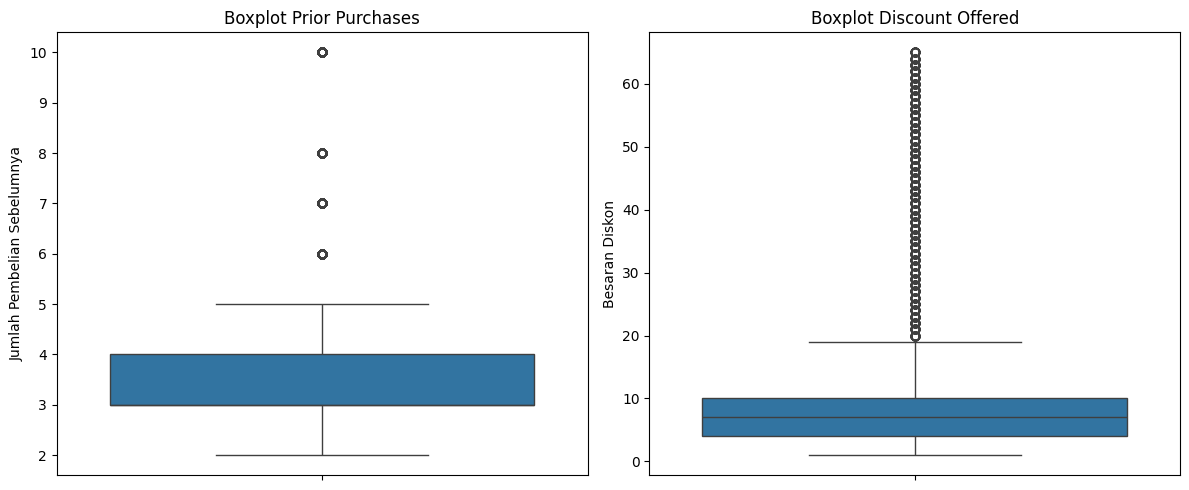

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Prior_purchases'], ax=axes[0])
axes[0].set_title('Boxplot Prior Purchases')
axes[0].set_ylabel('Jumlah Pembelian Sebelumnya')

sns.boxplot(y=df['Discount_offered'], ax=axes[1])
axes[1].set_title('Boxplot Discount Offered')
axes[1].set_ylabel('Besaran Diskon')

plt.tight_layout()
plt.show()

In [32]:
print(
    df['Discount_offered']
    .value_counts()
    .sort_index()
)

Discount_offered
1     824
2     858
3     840
4     825
5     810
     ... 
61     53
62     49
63     53
64     43
65     36
Name: count, Length: 65, dtype: int64


In [34]:
import pandas as pd
from scipy.stats import chi2_contingency

# 1. Membuat tabel kontingensi
tabel = pd.crosstab(
    df['Mode_of_Shipment'],
    df['Reached.on.Time_Y.N']
)

# Memberikan nama kolom agar mudah dibaca
tabel.columns = ['Tepat Waktu', 'Terlambat']

print("Tabel Frekuensi Pengiriman:")
print(tabel)

# 2. Menghitung persentase keterlambatan setiap moda
persentase = (
    tabel['Terlambat'] / tabel.sum(axis=1)
) * 100

print("\nPersentase Keterlambatan:")
print(persentase.round(2))

# 3. Melakukan Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(tabel)

print("\nHasil Chi-Square Test:")
print(f"Chi-Square Statistic : {chi2:.4f}")
print(f"P-value              : {p_value:.6f}")
print(f"Degrees of Freedom   : {dof}")

# 4. Interpretasi berdasarkan tingkat signifikansi
alpha = 0.05

if p_value < alpha:
    print("\nKesimpulan: Terdapat hubungan yang signifikan")
    print("antara moda pengiriman dan keterlambatan.")
else:
    print("\nKesimpulan: Tidak terdapat bukti hubungan")
    print("yang signifikan antara moda pengiriman dan keterlambatan.")

Tabel Frekuensi Pengiriman:
                  Tepat Waktu  Terlambat
Mode_of_Shipment                        
Flight                    708       1069
Road                      725       1035
Ship                     3003       4459

Persentase Keterlambatan:
Mode_of_Shipment
Flight    60.16
Road      58.81
Ship      59.76
dtype: float64

Hasil Chi-Square Test:
Chi-Square Statistic : 0.7434
P-value              : 0.689549
Degrees of Freedom   : 2

Kesimpulan: Tidak terdapat bukti hubungan
yang signifikan antara moda pengiriman dan keterlambatan.
